# Last-Mile Delivery ETA Prediction

Predicting urban food and parcel delivery duration using Haversine geospatial distance, traffic density, weather regimes, preparation lead time, and multi-order batching.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score
import lightgbm as lgb

sns.set_theme(style="whitegrid")
plt.rcParams["font.sans-serif"] = "DejaVu Sans"
plt.rcParams["figure.dpi"] = 140

print("Environment initialized for geospatial delivery ETA modeling.")

Environment initialized for geospatial delivery ETA modeling.


## Dataset Sanity Check & Haversine Distance Calculation

Inspecting raw order logs for missing values, checking feature distributions, and computing great-circle travel distance directly from merchant and customer WGS84 coordinates.

In [2]:
def haversine_km(lat1, lon1, lat2, lon2):
    earth_radius_km = 6371.0
    lat1_rad, lon1_rad = np.radians(lat1), np.radians(lon1)
    lat2_rad, lon2_rad = np.radians(lat2), np.radians(lon2)
    dlat = lat2_rad - lat1_rad
    dlon = lon2_rad - lon1_rad
    a = np.sin(dlat / 2.0) ** 2 + np.cos(lat1_rad) * np.cos(lat2_rad) * np.sin(dlon / 2.0) ** 2
    return 2.0 * earth_radius_km * np.arcsin(np.sqrt(a))

df = pd.read_csv("dataset/delivery_eta_dataset.csv")
df["haversine_distance_km"] = haversine_km(
    df["restaurant_lat"], df["restaurant_lon"],
    df["delivery_lat"], df["delivery_lon"]
).round(2)

print(f"Dataset shape: {df.shape[0]:,} orders | {df.shape[1]} columns | Total nulls: {df.isna().sum().sum()}")
print(f"Mean delivery time: {df['delivery_time_mins'].mean():.2f} mins (std: {df['delivery_time_mins'].std():.2f} mins)")
df[["haversine_distance_km", "prep_time_mins", "driver_rating", "multiple_deliveries", "delivery_time_mins"]].describe().T[["mean", "std", "min", "50%", "max"]].round(2)

Dataset shape: 5,000 orders | 16 columns | Total nulls: 0
Mean delivery time: 30.52 mins (std: 14.27 mins)


,mean,std,min,50%,max
haversine_distance_km,4.41,2.85,0.44,3.81,12.79
prep_time_mins,11.68,5.34,4.00,10.80,28.00
driver_rating,4.83,0.11,4.17,4.85,5.00
multiple_deliveries,0.41,0.64,0.00,0.00,2.00
delivery_time_mins,30.52,14.27,10.00,28.00,95.00


## Exploratory Analysis: Distance, Traffic, and Weather Effects

Evaluating how physical travel distance interacts with road congestion and weather severity to drive non-linear delivery delays.

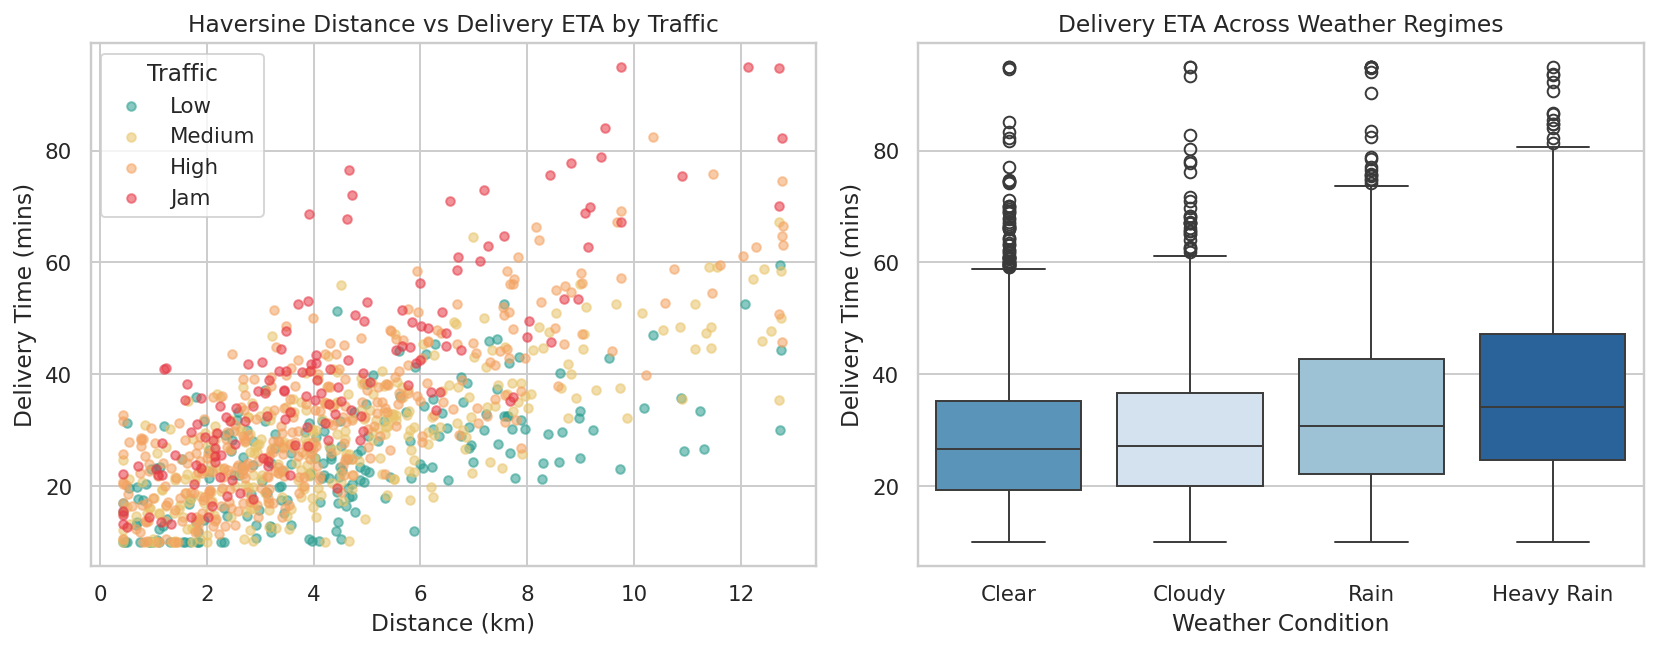

In [3]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.8))
traffic_palette = {"Low": "#2A9D8F", "Medium": "#E9C46A", "High": "#F4A261", "Jam": "#E63946"}
sample_df = df.sample(1000, random_state=42)

for level in ["Low", "Medium", "High", "Jam"]:
    sub = sample_df[sample_df["traffic_density"] == level]
    ax1.scatter(sub["haversine_distance_km"], sub["delivery_time_mins"],
                color=traffic_palette[level], alpha=0.55, s=20, label=level)

ax1.set_title("Haversine Distance vs Delivery ETA by Traffic")
ax1.set_xlabel("Distance (km)")
ax1.set_ylabel("Delivery Time (mins)")
ax1.legend(title="Traffic")

sns.boxplot(data=df, x="weather_condition", y="delivery_time_mins",
            order=["Clear", "Cloudy", "Rain", "Heavy Rain"],
            hue="weather_condition", palette="Blues", legend=False, ax=ax2)
ax2.set_title("Delivery ETA Across Weather Regimes")
ax2.set_xlabel("Weather Condition")
ax2.set_ylabel("Delivery Time (mins)")

plt.tight_layout()
plt.show()

## Model Training & Pipeline Benchmarking

Comparing Ridge Regression against Random Forest and LightGBM inside a unified preprocessing pipeline on an 80/20 holdout split.

In [4]:
numeric_features = [
    "haversine_distance_km", "order_hour", "is_weekend", "is_peak_hour",
    "driver_rating", "prep_time_mins", "multiple_deliveries"
]
categorical_features = ["weather_condition", "traffic_density", "vehicle_type"]
feature_cols = numeric_features + categorical_features

X = df[feature_cols]
y = df["delivery_time_mins"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_features),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categorical_features),
    ]
)

models = {
    "Ridge Regression": Ridge(alpha=1.0),
    "Random Forest": RandomForestRegressor(n_estimators=160, max_depth=12, min_samples_leaf=4, random_state=42, n_jobs=-1),
    "LightGBM Regressor": lgb.LGBMRegressor(n_estimators=240, learning_rate=0.04, num_leaves=31, subsample=0.85, random_state=42, verbose=-1),
}

records = []
preds = {}
pipelines = {}

for name, est in models.items():
    pipe = Pipeline([("preprocessor", preprocessor), ("regressor", est)])
    pipe.fit(X_train, y_train)
    y_pred = pipe.predict(X_test)
    records.append({
        "Model": name,
        "MAE (mins)": round(mean_absolute_error(y_test, y_pred), 3),
        "RMSE (mins)": round(root_mean_squared_error(y_test, y_pred), 3),
        "R2": round(r2_score(y_test, y_pred), 4),
        "SLA +-5m (%)": round(np.mean(np.abs(y_test - y_pred) <= 5.0) * 100.0, 2),
    })
    preds[name] = y_pred
    pipelines[name] = pipe

benchmark_df = pd.DataFrame(records)
benchmark_df

,Model,MAE (mins),RMSE (mins),R2,SLA +-5m (%)
0,Ridge Regression,3.648,4.783,0.8850,74.4
1,Random Forest,3.488,4.707,0.8887,76.7
2,LightGBM Regressor,2.994,3.924,0.9226,81.0


## Segment Error Breakdown & Residual Diagnostics

Checking where prediction errors concentrate across traffic congestion levels and verifying residual symmetry on the holdout set.

Holdout Error Breakdown by Traffic Density (LightGBM):


,orders,mean_actual,mae_mins,sla_5m_pct
traffic_density,,,,
Low,206,24.67,2.67,84.95
Medium,315,28.47,2.83,81.27
High,333,31.56,3.11,81.08
Jam,146,40.71,3.54,74.66


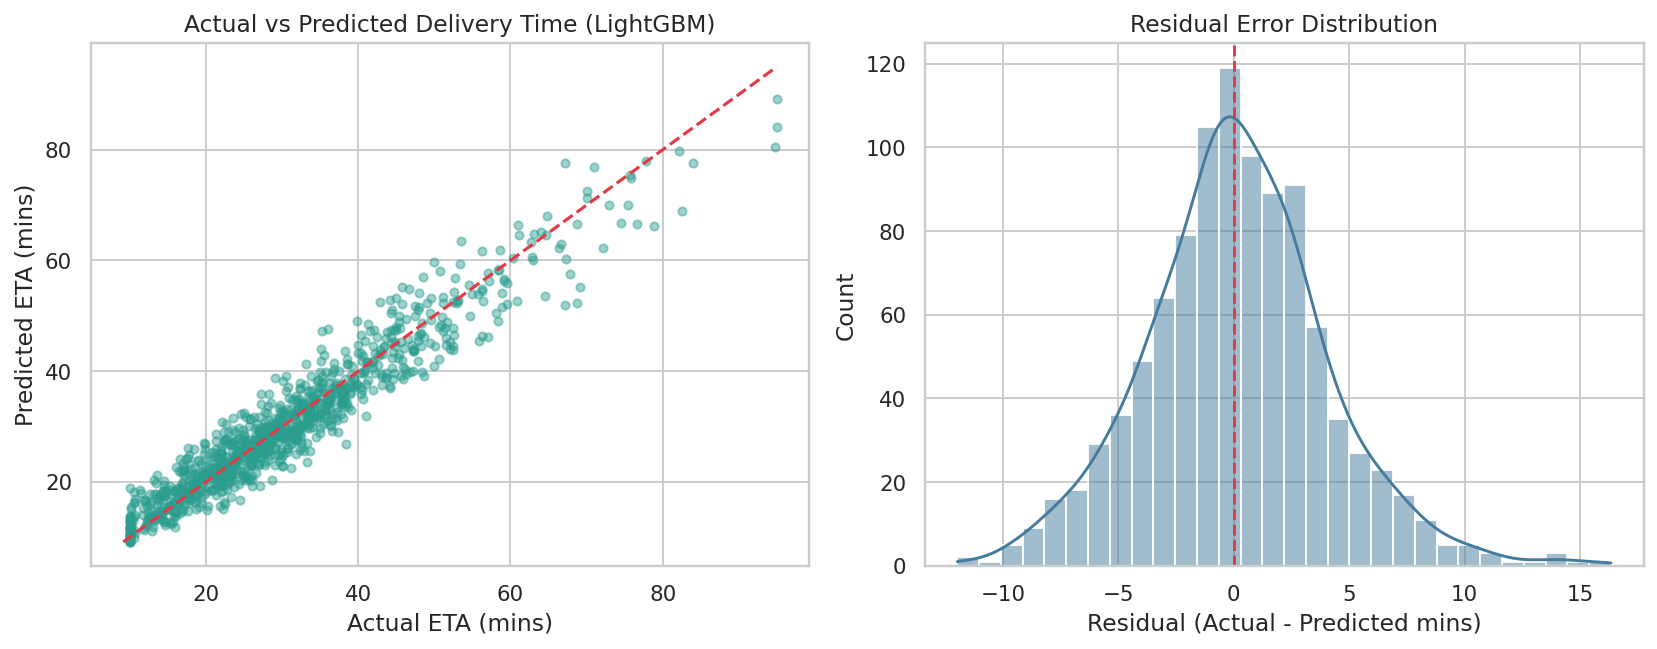

In [5]:
lgbm_pred = preds["LightGBM Regressor"]
residuals = y_test - lgbm_pred

eval_df = X_test.copy()
eval_df["actual_eta"] = y_test
eval_df["pred_eta"] = lgbm_pred
eval_df["abs_err"] = np.abs(residuals)
eval_df["within_5m"] = (eval_df["abs_err"] <= 5.0).astype(int)

traffic_audit = eval_df.groupby("traffic_density").agg(
    orders=("actual_eta", "count"),
    mean_actual=("actual_eta", "mean"),
    mae_mins=("abs_err", "mean"),
    sla_5m_pct=("within_5m", lambda s: s.mean() * 100.0)
).reindex(["Low", "Medium", "High", "Jam"]).round(2)

print("Holdout Error Breakdown by Traffic Density (LightGBM):")
display(traffic_audit)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.8))
ax1.scatter(y_test, lgbm_pred, alpha=0.45, s=18, color="#2A9D8F")
lims = [min(y_test.min(), lgbm_pred.min()), max(y_test.max(), lgbm_pred.max())]
ax1.plot(lims, lims, "--", color="#E63946", lw=1.6)
ax1.set_title("Actual vs Predicted Delivery Time (LightGBM)")
ax1.set_xlabel("Actual ETA (mins)")
ax1.set_ylabel("Predicted ETA (mins)")

sns.histplot(residuals, bins=30, kde=True, color="#457B9D", ax=ax2)
ax2.axvline(0, color="#E63946", linestyle="--", lw=1.5)
ax2.set_title("Residual Error Distribution")
ax2.set_xlabel("Residual (Actual - Predicted mins)")

plt.tight_layout()
plt.show()

## Feature Importance & Artifact Export

Inspecting dominant ETA drivers and exporting the end-to-end preprocessing and prediction pipeline.

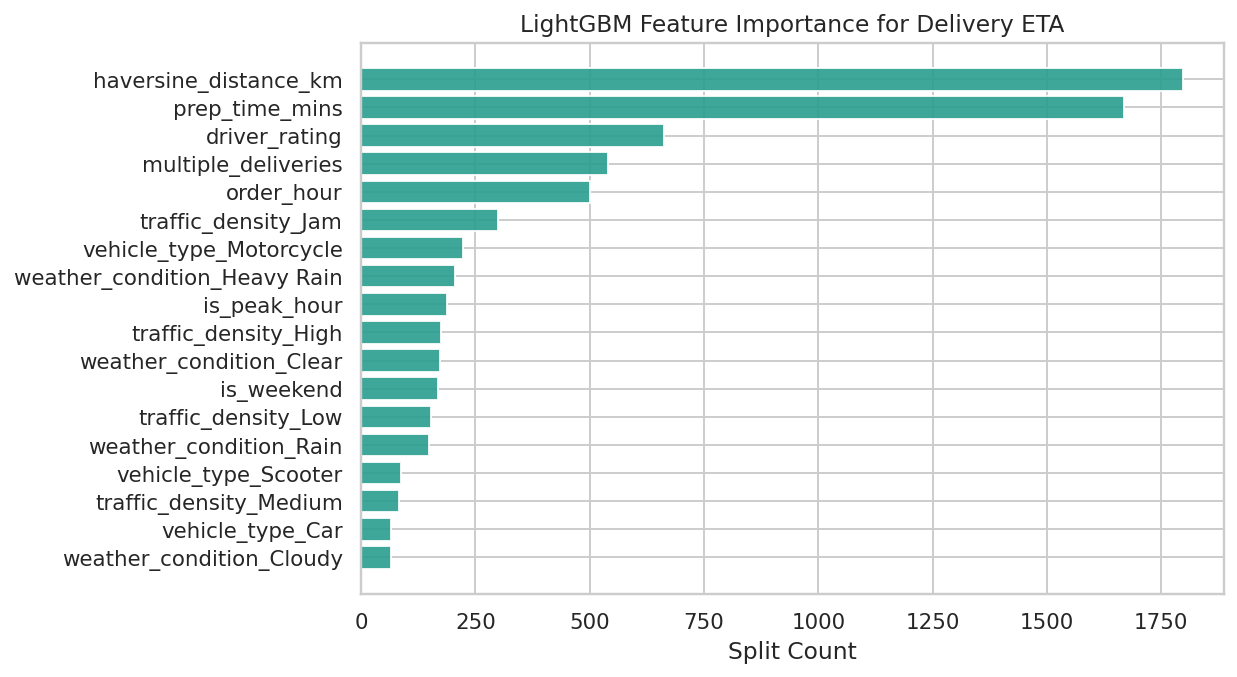

Saved models/delivery_eta_pipeline.joblib


In [6]:
best_pipe = pipelines["LightGBM Regressor"]
ohe_names = best_pipe.named_steps["preprocessor"].named_transformers_["cat"].get_feature_names_out(categorical_features)
all_names = numeric_features + list(ohe_names)
imp_df = pd.DataFrame({
    "feature": all_names,
    "importance": best_pipe.named_steps["regressor"].feature_importances_,
}).sort_values("importance", ascending=True)

plt.figure(figsize=(9, 5))
plt.barh(imp_df["feature"], imp_df["importance"], color="#2A9D8F", alpha=0.9)
plt.title("LightGBM Feature Importance for Delivery ETA")
plt.xlabel("Split Count")
plt.tight_layout()
plt.show()

artifact = {
    "pipeline": best_pipe,
    "numeric_features": numeric_features,
    "categorical_features": categorical_features,
    "feature_cols": feature_cols,
    "metrics": benchmark_df.to_dict(orient="records"),
}
joblib.dump(artifact, "models/delivery_eta_pipeline.joblib")
print("Saved models/delivery_eta_pipeline.joblib")